# Why We Built a Walking Robot Duck Twice

The same ONNX policy walks the Modelica plant (DuckPlant.fmu, stepped from Python) and the MuJoCo training model. Change the command or the supply and compare. The policy runs here in Python at 50 Hz with the 22.5 ms command delay of training; `walk_fmu(command_delay=0.023)` reproduces the OpenModelica runs quoted in the posts, whose fixed-step solver applied the delay at the next 1 ms step.

[Setup and files](README.md).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
from common import *  # noqa: F403  FMU and MuJoCo helpers, plot style

%matplotlib inline

## Walk both simulators

The FMU walk takes about 45 s for 6 s; MuJoCo about a second.

In [2]:
duck = walk_fmu()
mj = walk_mujoco(speed_command=0.3)
print(f"Duck library {speed(duck):.3f} m/s, MuJoCo {speed(mj):.3f} m/s over the last 4 s")
print(f"distance after 6 s: {duck['distance'].iloc[-1]:.2f} m against {mj['distance'].iloc[-1]:.2f} m")

Duck library 0.138 m/s, MuJoCo 0.132 m/s over the last 4 s
distance after 6 s: 0.79 m against 0.80 m


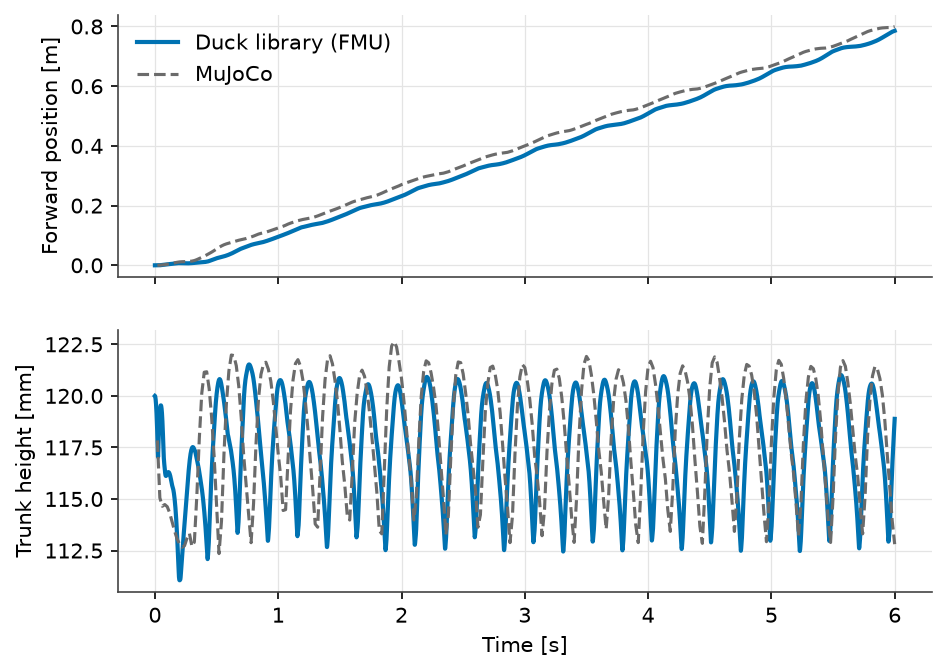

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
a1.plot(duck["time"], duck["distance"], color=BLUE, label="Duck library (FMU)")
a1.plot(mj["time"], mj["distance"], color=GREY, ls="--", lw=1.5, label="MuJoCo")
a2.plot(duck["time"], 1e3 * duck["trunkHeight"], color=BLUE)
a2.plot(mj["time"], 1e3 * mj["trunkHeight"], color=GREY, ls="--", lw=1.5)
a1.set_ylabel("Forward position [m]"); a1.legend()
a2.set_ylabel("Trunk height [mm]"); a2.set_xlabel("Time [s]")
plt.show()

## Change the supply

The policy was trained at 6.5 to 8.2 V. Part 3 sweeps this in full.

In [4]:
low = walk_fmu(supply=6.5)
print(f"6.5 V: {speed(low):.3f} m/s, mean servo power {6.5 * low['batteryCurrent'][low['time'] >= 2].mean():.2f} W")

6.5 V: 0.133 m/s, mean servo power 2.11 W
